# Week 4: from messy data to model-ready (student social-media data)

This notebook works through the 12-step preprocessing workflow on `dataset.csv`: 5,000 students, their social-media habits, sleep, study time and a `Mental_Health_Score` (roughly 1–10).

**Goal:** prepare the data to predict `Mental_Health_Score`. There is no model yet; that comes in Week 5.

**How to run it:** select the `.venv` kernel, then click **Run All**. The cells must run top to bottom, because each one uses variables from the ones before it.

## Setup
Load the libraries, then the data.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer

In [20]:
# dataset.csv lives in the data/ folder next to this notebook.
DATA_PATH = "data/dataset.csv"

students = pd.read_csv(DATA_PATH)
students.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


## B1. Inspect
Three checks: shape and types, then missing values, duplicates and summary statistics, then category counts.

In [21]:
print("Rows, columns:", students.shape)
students.info()

Rows, columns: (5000, 13)
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   str    
 2   Country                  5000 non-null   str    
 3   Academic_Level           5000 non-null   str    
 4   Most_Used_Platform       5000 non-null   str    
 5   Purpose_Of_Use           5000 non-null   str    
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   str    
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), str(6)
memory usage: 507.9 KB


In [22]:
print("Missing values:", int(students.isna().sum().sum()))
print("Exact duplicate rows:", students.duplicated().sum())
students.describe().round(2)

Missing values: 0
Exact duplicate rows: 2


,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,20.82,5.08,171.45,3.01,1.75,6.63,6.23
std,1.74,1.65,42.86,1.64,0.67,1.22,1.28
min,18.00,1.00,62.00,0.30,-0.40,3.60,3.60
25%,19.00,3.80,140.00,1.50,1.30,5.60,5.10
50%,21.00,5.00,171.00,2.80,1.70,6.60,6.10
75%,22.00,6.30,204.00,4.20,2.20,7.50,7.10
max,24.00,8.80,273.00,8.30,4.10,9.90,9.40


In [23]:
st_categorical = ["Gender", "Country", "Academic_Level", "Most_Used_Platform",
                  "Purpose_Of_Use", "Stress_Level"]
for col in st_categorical:
    counts = students[col].value_counts(dropna=False)
    print(f"--- {col} ({counts.size} categories) ---")
    print(counts.head(8), "\n")

--- Gender (2 categories) ---
Gender
Male      2635
Female    2365
Name: count, dtype: int64 

--- Country (111 categories) ---
Country
Other        1880
India         389
USA           355
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Name: count, dtype: int64 

--- Academic_Level (3 categories) ---
Academic_Level
Undergraduate    3632
Graduate          918
High School       450
Name: count, dtype: int64 

--- Most_Used_Platform (12 categories) ---
Most_Used_Platform
Instagram    1130
TikTok        918
Facebook      719
LinkedIn      523
YouTube       491
Twitter       462
Snapchat      420
WhatsApp      175
Name: count, dtype: int64 

--- Purpose_Of_Use (4 categories) ---
Purpose_Of_Use
Entertainment    2552
Education        1094
Networking        793
News              561
Name: count, dtype: int64 

--- Stress_Level (4 categories) ---
Stress_Level
Very High    1621
High         1440
Medium       1295
Low           644
Name: count, dtype: i

**What the output shows**

- **5,000 rows × 13 columns** with **no missing values**. The dataset is fairly clean.
- **2 exact duplicate rows.**
- **Read the min and max:** `Physical_Activity_Hours` has a **minimum of −0.4**, which is impossible because nobody exercises for negative hours. Everything else is plausible: ages 18–24, sleep 3.6–9.9 h.
- `Country` has **over 100 categories**, many with only a handful of students. This matters for encoding in B9.
- The labels are already consistent (`Male`/`Female`, three academic levels).

## B2. Row-wise cleaning (before the split)
1. Drop exact duplicates.
2. Strip stray spaces from text labels, as a safety rule. There are no spelling variants here.
3. Set **impossible** values to `NaN`: negative hours, or more than 24 hours in a day.

In [24]:
st_clean = students.drop_duplicates().copy()

for col in st_categorical:
    st_clean[col] = st_clean[col].str.strip()

hour_cols = ["Avg_Daily_Usage_Hours", "Study_Hours",
             "Physical_Activity_Hours", "Sleep_Hours_Per_Night"]
for col in hour_cols:
    impossible = (st_clean[col] < 0) | (st_clean[col] > 24)
    print(f"{col}: {impossible.sum()} impossible values set to NaN")
    st_clean.loc[impossible, col] = np.nan

# Sanity check across columns: total hours per day can't exceed 24.
total_hours = st_clean[hour_cols].sum(axis=1)
print("\nMaximum total hours in one day:", total_hours.max())
print("Rows after removing duplicates:", len(st_clean))

Avg_Daily_Usage_Hours: 0 impossible values set to NaN
Study_Hours: 0 impossible values set to NaN
Physical_Activity_Hours: 10 impossible values set to NaN
Sleep_Hours_Per_Night: 0 impossible values set to NaN

Maximum total hours in one day: 22.1
Rows after removing duplicates: 4998


In [25]:
# Checkpoint
assert st_clean.duplicated().sum() == 0, "Duplicates remain"
assert (st_clean[hour_cols].dropna() >= 0).all().all(), "Negative hours remain"
assert (st_clean[hour_cols].dropna() <= 24).all().all(), "More than 24 hours remain"
print("B2 checks passed:", st_clean.shape)

B2 checks passed: (4998, 13)


## B3. Target and features — check for target leakage

Target: `Mental_Health_Score`.

**Think:** is `Stress_Level` a *cause* we could know in advance, or **another measurement of the same outcome**, recorded at the same moment?

**Decision:** we **drop `Stress_Level`** from the features. It's self-reported in the same questionnaire as the target and measures closely related wellbeing (average score is 7.8 for *Low* stress and 5.1 for *Very High*). If we want to predict mental health from **behaviour**, stress is part of the outcome, not an input. A model using it would mostly be learning "unhappy people report being unhappy".

*This is a judgement call. If stress were measured earlier, for example at the start of term, it could be a legitimate feature. Write down whichever choice you make and why.*

There's no ID column to remove.

In [26]:
st_target = "Mental_Health_Score"
st_leaky = ["Stress_Level"]

print(students.groupby("Stress_Level")[st_target].mean().round(2).sort_values())

st_X = st_clean.drop(columns=[st_target] + st_leaky)
st_y = st_clean[st_target]
print("\nFeatures used:", st_X.columns.tolist())

Stress_Level
Very High    5.05
High         6.03
Medium       7.14
Low          7.84
Name: Mental_Health_Score, dtype: float64

Features used: ['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night']


## B4. Train / test split

In [27]:
st_X_train, st_X_test, st_y_train, st_y_test = train_test_split(
    st_X, st_y, test_size=0.2, random_state=42
)
print("train:", st_X_train.shape, " test:", st_X_test.shape)

# Working copies for the manual steps B5–B10; the originals are kept for the pipeline in B11.
sXtr, sXte = st_X_train.copy(), st_X_test.copy()

train: (3998, 11)  test: (1000, 11)


## B5. Missing values
The only gaps are the ones **we created** in B2 (negative activity hours). Physical activity is a skewed count of hours, so we use the **training median**.

In [28]:
st_numeric = ["Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks", "Study_Hours",
              "Physical_Activity_Hours", "Sleep_Hours_Per_Night"]

print("Missing in train before:")
print(sXtr.isna().sum()[sXtr.isna().sum() > 0])

st_medians = sXtr[st_numeric].median()          # learned from TRAIN only
sXtr[st_numeric] = sXtr[st_numeric].fillna(st_medians)
sXte[st_numeric] = sXte[st_numeric].fillna(st_medians)

print("\nMissing after:", int(sXtr.isna().sum().sum()), "train /", int(sXte.isna().sum().sum()), "test")

Missing in train before:
Physical_Activity_Hours    8
dtype: int64

Missing after: 0 train / 0 test


## B6. Outliers
We use the IQR rule (values beyond 1.5 × IQR from the quartiles) to *flag* unusual values. Flagged values are investigated, not automatically deleted.

Values flagged by the IQR rule (train):
Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    10
Sleep_Hours_Per_Night       0
dtype: int64


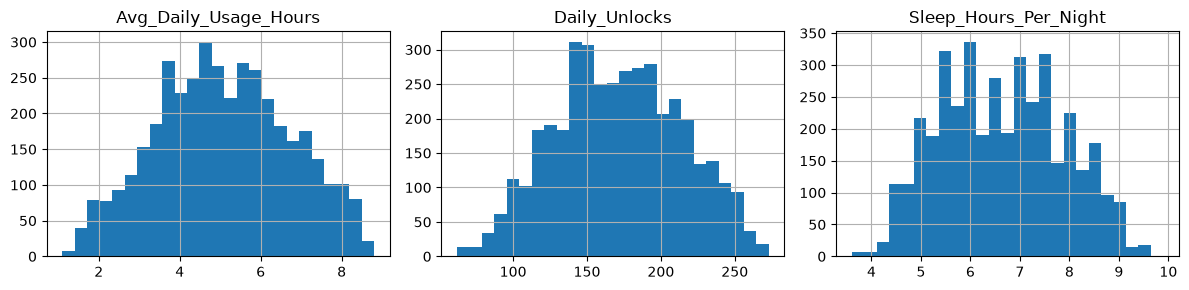

In [29]:
q1, q3 = sXtr[st_numeric].quantile(0.25), sXtr[st_numeric].quantile(0.75)
iqr = q3 - q1
flagged = ((sXtr[st_numeric] < q1 - 1.5 * iqr) | (sXtr[st_numeric] > q3 + 1.5 * iqr)).sum()
print("Values flagged by the IQR rule (train):")
print(flagged)

sXtr[["Avg_Daily_Usage_Hours", "Daily_Unlocks", "Sleep_Hours_Per_Night"]].hist(bins=25, figsize=(12, 3), layout=(1, 3))
plt.tight_layout()
plt.show()

**Answer:** Only a few values are flagged, and all of them are plausible: about 9 hours of social media a day, or 270 phone unlocks. These are heavy users, not errors, and they're exactly the students whose wellbeing we care most about. **We keep them.**

## B7. Dates
`dataset.csv` has **no date column**, so this step doesn't apply. In real projects, check whether "no date" means the data really is a single snapshot. If it is, the model can't learn anything about change over time.

## B8. Feature engineering
Three new features, created from the original units before encoding and scaling:

1. **`social_to_study_ratio`** — social-media hours per study hour. The *balance* between the two may matter more than either one on its own.
2. **`unlocks_per_usage_hour`** — how often the phone is picked up per hour of use. Many short, compulsive checks are different from a few long sessions.
3. **`sleep_deficit`** — hours below the recommended 7 hours of sleep (0 if 7 or more). This captures the idea that lack of sleep hurts, while extra sleep beyond 7 hours doesn't keep helping.

In [30]:
def st_add_features(data):
    result = data.copy()
    result["social_to_study_ratio"] = (
        result["Avg_Daily_Usage_Hours"] / result["Study_Hours"].clip(lower=0.1)
    )
    result["unlocks_per_usage_hour"] = (
        result["Daily_Unlocks"] / result["Avg_Daily_Usage_Hours"].clip(lower=0.1)
    )
    result["sleep_deficit"] = (7 - result["Sleep_Hours_Per_Night"]).clip(lower=0)
    return result

sXtr = st_add_features(sXtr)
sXte = st_add_features(sXte)

st_new = ["social_to_study_ratio", "unlocks_per_usage_hour", "sleep_deficit"]
# Quick check: how does each new feature relate to the target in TRAIN?
print(sXtr[st_new].corrwith(st_y_train).round(2))
sXtr[st_new].head()

social_to_study_ratio    -0.67
unlocks_per_usage_hour    0.59
sleep_deficit            -0.70
dtype: float64


,social_to_study_ratio,unlocks_per_usage_hour,sleep_deficit
1738,1.545455,35.490196,0.0
3988,0.271186,61.250000,0.0
2917,1.600000,42.250000,0.0
1595,2.071429,35.172414,0.3
3215,14.800000,31.351351,2.0


## B9. Encoding
| Column | Type | Encoder |
|---|---|---|
| `Academic_Level` | ordinal (High School < Undergraduate < Graduate) | `OrdinalEncoder`, explicit order |
| `Gender`, `Most_Used_Platform`, `Purpose_Of_Use` | nominal | `OneHotEncoder` |
| `Country` | nominal with **100+ categories** | `OneHotEncoder(min_frequency=20)`: rare countries are grouped into one *infrequent* column |

**Why `min_frequency`?** Without it, `Country` alone would create over 100 columns, most of them almost always 0. A country seen only twice in training can't teach the model anything reliable.

In [31]:
st_level_order = ["High School", "Undergraduate", "Graduate"]
st_ordinal_enc = OrdinalEncoder(categories=[st_level_order])
sXtr[["Academic_Level"]] = st_ordinal_enc.fit_transform(sXtr[["Academic_Level"]])
sXte[["Academic_Level"]] = st_ordinal_enc.transform(sXte[["Academic_Level"]])

st_nominal = ["Gender", "Country", "Most_Used_Platform", "Purpose_Of_Use"]
st_onehot = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                          sparse_output=False)
tr_nom = pd.DataFrame(st_onehot.fit_transform(sXtr[st_nominal]),
                      columns=st_onehot.get_feature_names_out(st_nominal), index=sXtr.index)
te_nom = pd.DataFrame(st_onehot.transform(sXte[st_nominal]),
                      columns=st_onehot.get_feature_names_out(st_nominal), index=sXte.index)

sXtr = pd.concat([sXtr.drop(columns=st_nominal), tr_nom], axis=1)
sXte = pd.concat([sXte.drop(columns=st_nominal), te_nom], axis=1)

print("Columns after encoding:", sXtr.shape[1])
print("Country columns:", [c for c in tr_nom.columns if c.startswith("Country")])

Columns after encoding: 58
Country columns: ['Country_Australia', 'Country_Bangladesh', 'Country_Brazil', 'Country_Canada', 'Country_China', 'Country_Denmark', 'Country_France', 'Country_Germany', 'Country_India', 'Country_Ireland', 'Country_Italy', 'Country_Japan', 'Country_Malaysia', 'Country_Maldives', 'Country_Mexico', 'Country_Nepal', 'Country_Netherlands', 'Country_Other', 'Country_Pakistan', 'Country_Poland', 'Country_Russia', 'Country_Singapore', 'Country_South Korea', 'Country_Spain', 'Country_Sri Lanka', 'Country_Switzerland', 'Country_Turkey', 'Country_UK', 'Country_USA', 'Country_infrequent_sklearn']


## B10. Scaling

In [32]:
st_scale_cols = st_numeric + st_new
st_scaler = StandardScaler()
sXtr[st_scale_cols] = st_scaler.fit_transform(sXtr[st_scale_cols])   # learn on train
sXte[st_scale_cols] = st_scaler.transform(sXte[st_scale_cols])       # reuse on test

print("Train means (should be ~0):", sXtr[st_scale_cols].mean().round(2).abs().max())
print("Test means (close to 0, but not exactly):")
print(sXte[st_scale_cols].mean().round(2))

Train means (should be ~0): 0.0
Test means (close to 0, but not exactly):
Age                        0.01
Avg_Daily_Usage_Hours     -0.01
Daily_Unlocks             -0.02
Study_Hours                0.03
Physical_Activity_Hours    0.02
Sleep_Hours_Per_Night     -0.01
social_to_study_ratio     -0.00
unlocks_per_usage_hour    -0.01
sleep_deficit              0.02
dtype: float64


## B11. The whole thing as one pipeline
Row-wise features first, then a `ColumnTransformer` that sends each group of columns to its own mini-pipeline. The imputers stay in the pipeline even though this dataset has almost no gaps, because **new data might**.

In [33]:
st_numeric_all = st_numeric + st_new

st_preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), st_numeric_all),
    ("ord", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("encode", OrdinalEncoder(categories=[st_level_order]))]), ["Academic_Level"]),
    ("nom", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                               min_frequency=20, sparse_output=False))]), st_nominal),
])

st_pipeline = Pipeline([
    ("features", FunctionTransformer(st_add_features)),
    ("preprocess", st_preprocessor),
])

st_train_prepared = st_pipeline.fit_transform(st_X_train)   # learn from train
st_test_prepared = st_pipeline.transform(st_X_test)         # reuse on test

print("Prepared train:", st_train_prepared.shape, "| test:", st_test_prepared.shape)
print("Missing values left:", int(np.isnan(st_train_prepared).sum()))
print("Same result as the manual steps:", st_train_prepared.shape[1] == sXtr.shape[1])

Prepared train: (3998, 58) | test: (1000, 58)
Missing values left: 0
Same result as the manual steps: True


## B12. Leakage, revisited

In [34]:
col = "Daily_Unlocks"
print(f"mean from ALL data   : {st_X[col].mean():.2f}")
print(f"mean from TRAIN only : {st_X_train[col].mean():.2f}")
print(f"SD   from ALL data   : {st_X[col].std():.2f}")
print(f"SD   from TRAIN only : {st_X_train[col].std():.2f}")

mean from ALL data   : 171.46
mean from TRAIN only : 171.65
SD   from ALL data   : 42.86
SD   from TRAIN only : 42.64


**Answer**

- **Preprocessing leakage:** the differences are tiny, but the scaler and imputer still learn from **train only**, so the test set remains a fair stand-in for new students.
- **Target leakage:** the risky column here is `Stress_Level`, not an obvious "after the fact" column such as a cancellation date. It is recorded at the same time and is strongly tied to the target, so it is really part of the outcome. A random split wouldn't flag it: the model would score very well, and the score would be misleading if the aim is to predict mental health from behaviour.

### Summary of decisions
| Step | Decision |
|---|---|
| Duplicates | 2 removed |
| Impossible values | negative `Physical_Activity_Hours` → `NaN` → train median |
| Target leakage | `Stress_Level` dropped (co-measured outcome) |
| Outliers | flagged, investigated, **kept** (plausible heavy users) |
| Dates | none in this dataset |
| New features | `social_to_study_ratio`, `unlocks_per_usage_hour`, `sleep_deficit` |
| Encoding | ordinal `Academic_Level`; one-hot for the rest, rare countries grouped |
| Scaling | `StandardScaler`, fitted on train |